# Online Retail Sales Analysis
## Revenue Trends, Top Products, and Customer Markets

**Author:** Henry Audi  
**Project type:** Individual academic portfolio project

## 1. Project Introduction

This project examines sales patterns in the UCI Online Retail dataset.
I used Python, Pandas, Matplotlib, and Seaborn to inspect and clean
the data, analyze sales performance, and communicate findings.

The dataset contains transaction line items from a UK-based online
retailer. Each row represents a product line on an invoice, rather
than a complete order.
I selected this dataset because it connects Python skills to practical business questions about sales trends, product performance, and customer markets. Its numerical, categorical, and date variables support meaningful cleaning, analysis, and visualization within one manageable dataset.

**Dataset:** Online Retail  
**Source:** UCI Machine Learning Repository  
**Link:** https://archive.ics.uci.edu/dataset/352/online+retail

### Research Questions

1. How do monthly sales value and order counts change across the
   complete months in the dataset?
2. Which products generate the highest sales value, and how do their
   rankings compare with rankings by units sold?
3. Which countries contribute the most sales value, and how does
   average order value differ across the leading markets?

### Results at a glance

- Prepared **522,538** merchandise lines from **541,909** original records.
- November 2011 led complete months with **£1,452,115.98** and **2,751** retained orders.
- Regency Cakestand led product sales value; Popcorn Holder led units sold.
- The UK contributed **84.77%** of retained sales value.

These results describe **gross positive merchandise sales after the stated exclusions**, not net revenue or profit. The two reviewed reversed purchases are excluded; other returns are not systematically matched.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## 2. Loading the Dataset

Run this notebook from the repository root. Download the original UCI workbook to `data/Online Retail.xlsx` using the README instructions. Python 3.11 and the package versions in `requirements.txt` were used for verification. The raw file remains unchanged.

In [2]:
data_path = Path("data") / "Online Retail.xlsx"

df_raw = pd.read_excel(
    data_path,
    dtype={
        "InvoiceNo": "string",
        "StockCode": "string",
        "CustomerID": "string",
    },
)

# Preserve the loaded data and use a separate copy for our work.
df = df_raw.copy()

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom


In [3]:
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")
print("\nColumn names:")
print(df.columns.tolist())

Rows: 541,909
Columns: 8

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  string        
 1   StockCode    541909 non-null  string        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  string        
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(1), int64(1), object(2), string(3)
memory usage: 33.1+ MB


In [5]:
df.isna().sum().sort_values(ascending=False)

CustomerID     135080
Description      1454
InvoiceNo           0
StockCode           0
Quantity            0
InvoiceDate         0
UnitPrice           0
Country             0
dtype: int64

In [6]:
print(f"Exact duplicate rows: {df.duplicated().sum():,}")

Exact duplicate rows: 5,268


## 3. Understanding the Dataset

The dataset contains 541,909 rows and eight columns. Each row represents
a product line on an invoice, so one invoice may appear on multiple rows.

Quantity and UnitPrice are numerical variables. InvoiceDate is a datetime
variable. InvoiceNo, StockCode, and CustomerID are identifiers stored as
text. Description and Country contain descriptive or categorical information.

CustomerID has 135,080 missing values, and Description has 1,454 missing
values. The remaining columns have no missing values. There are also
5,268 exact duplicate rows beyond their first occurrence.

Missing customer IDs do not automatically prevent sales analysis because
invoice numbers, quantities, prices, and countries are available.
Repeated invoice numbers are expected because an order can contain
multiple products. Exact duplicate rows require further investigation
before deciding whether to remove them.

In [7]:
display(df[["Quantity", "UnitPrice"]].describe())

print("Earliest invoice:", df["InvoiceDate"].min())
print("Latest invoice:", df["InvoiceDate"].max())

Earliest invoice: 2010-12-01 08:26:00
Latest invoice: 2011-12-09 12:50:00


,Quantity,UnitPrice
count,541909.000000,541909.000000
mean,9.552250,4.611114
std,218.081158,96.759853
min,-80995.000000,-11062.060000
25%,1.000000,1.250000
50%,3.000000,2.080000
75%,10.000000,4.130000
max,80995.000000,38970.000000


In [8]:
# UCI identifies invoice numbers beginning with C as cancellations.
cancellation_mask = (
    df["InvoiceNo"].str.upper().str.startswith("C", na=False)
)

quality_checks = pd.Series({
    "Cancellation rows": cancellation_mask.sum(),
    "Rows with negative quantity": (df["Quantity"] < 0).sum(),
    "Rows with zero quantity": (df["Quantity"] == 0).sum(),
    "Rows with negative unit price": (df["UnitPrice"] < 0).sum(),
    "Rows with zero unit price": (df["UnitPrice"] == 0).sum(),
    "Negative quantity without cancellation code": (
        (df["Quantity"] < 0) & ~cancellation_mask
    ).sum(),
})

display(quality_checks)

Cancellation rows                               9288
Rows with negative quantity                    10624
Rows with zero quantity                            0
Rows with negative unit price                      2
Rows with zero unit price                       2515
Negative quantity without cancellation code     1336
dtype: int64

In [9]:
columns_to_review = [
    "InvoiceNo", "StockCode", "Description",
    "Quantity", "InvoiceDate", "UnitPrice",
    "CustomerID", "Country"
]

print("Examples of cancellation records:")
display(df.loc[cancellation_mask, columns_to_review].head())

print("Examples with zero or negative prices:")
display(
    df.loc[df["UnitPrice"] <= 0, columns_to_review].head()
)

print("Examples of exact duplicate records:")
display(
    df.loc[df.duplicated(keep=False), columns_to_review].head(10)
)

Examples of cancellation records:
Examples with zero or negative prices:
Examples of exact duplicate records:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548,United Kingdom


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,<NA>,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,<NA>,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,<NA>,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,<NA>,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,<NA>,United Kingdom


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908,United Kingdom
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908,United Kingdom
548,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920,United Kingdom
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920,United Kingdom


## 4. Data Cleaning

For the main analysis, I will examine positive sales records: rows without
a cancellation invoice code, with Quantity greater than zero and
UnitPrice greater than zero. Excluded records will remain available in
the original dataset.

Sales value will be calculated as Quantity multiplied by UnitPrice,
in British pounds. This measures gross positive sales value rather
than net revenue after refunds or profit.

I will retain records with missing CustomerID because the research
questions use invoices, products, and countries rather than individual
customer identities. Missing customer IDs will remain missing.

For the primary analysis, I will retain one occurrence of each exact
duplicate row. This is an analytical assumption: the dataset has no
unique line-item identifier to establish whether identical rows are
errors or legitimate repeated entries. I will measure the effect of
this decision on sales value.

I will standardize surrounding whitespace in text fields. Products
will be grouped by StockCode rather than Description because product
descriptions can vary.

Unusually large quantities or prices will be inspected before deciding
whether additional exclusions are justified. Non-product charges will
also be reviewed before product rankings are calculated.

December 2011 is only partially observed and will be excluded from
complete-month comparisons.

In [10]:
# Start from the original data so rerunning this cell is safe.
working = df_raw.copy()

is_cancellation = (
    working["InvoiceNo"]
    .str.strip()
    .str.upper()
    .str.startswith("C", na=False)
)

positive_sales_mask = (
    ~is_cancellation
    & working["Quantity"].gt(0)
    & working["UnitPrice"].gt(0)
)

# Keep both versions to assess the duplicate-removal assumption.
sales_with_duplicates = working.loc[positive_sales_mask].copy()

sales = (
    sales_with_duplicates
    .drop_duplicates()
    .copy()
)

# Standardize text without inventing missing customer identities.
for column in [
    "InvoiceNo", "StockCode", "Description", "CustomerID", "Country"
]:
    sales[column] = sales[column].astype("string").str.strip()
    sales[column] = sales[column].replace("", pd.NA)

sales["InvoiceNo"] = sales["InvoiceNo"].str.upper()
sales["StockCode"] = sales["StockCode"].str.upper()

sales["SalesValue"] = sales["Quantity"] * sales["UnitPrice"]
sales["Month"] = sales["InvoiceDate"].dt.to_period("M")

display(sales.head())

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,SalesValue,Month
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30,2010-12
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00,2010-12
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12


In [11]:
cleaning_summary = pd.Series({
    "Original rows": len(df_raw),
    "Rows excluded by cancellation/quantity/price rules":
        len(df_raw) - len(sales_with_duplicates),
    "Positive-sales rows before duplicate removal":
        len(sales_with_duplicates),
    "Exact duplicate rows removed from positive sales":
        len(sales_with_duplicates) - len(sales),
    "Positive-sales rows retained": len(sales),
    "Remaining missing customer IDs": sales["CustomerID"].isna().sum(),
    "Remaining missing descriptions": sales["Description"].isna().sum(),
})

display(cleaning_summary)

value_before = (
    sales_with_duplicates["Quantity"]
    * sales_with_duplicates["UnitPrice"]
).sum()

value_after = sales["SalesValue"].sum()

print(f"Sales value before duplicate removal: £{value_before:,.2f}")
print(f"Sales value after duplicate removal: £{value_after:,.2f}")
print(
    "Percentage reduction from duplicate removal: "
    f"{100 * (value_before - value_after) / value_before:.2f}%"
)

Sales value before duplicate removal: £10,666,684.54
Sales value after duplicate removal: £10,642,110.80
Percentage reduction from duplicate removal: 0.23%


Original rows                                         541909
Rows excluded by cancellation/quantity/price rules     11805
Positive-sales rows before duplicate removal          530104
Exact duplicate rows removed from positive sales        5226
Positive-sales rows retained                          524878
Remaining missing customer IDs                        132186
Remaining missing descriptions                             0
dtype: int64

In [12]:
review_columns = [
    "InvoiceNo", "StockCode", "Description",
    "Quantity", "UnitPrice", "SalesValue", "Country"
]

print("Ten largest line-item sales values:")
display(
    sales.nlargest(10, "SalesValue")[review_columns]
)

print("Ten highest unit prices:")
display(
    sales.nlargest(10, "UnitPrice")[review_columns]
)

# Flag codes for inspection, without automatically removing them.
# Regular merchandise codes commonly have five digits and optional letters.
unusual_code_mask = ~sales["StockCode"].str.fullmatch(
    r"\d{5}[A-Z]*", na=False
)

print("Examples of other stock codes:")
display(
    sales.loc[
        unusual_code_mask,
        ["StockCode", "Description"]
    ]
    .drop_duplicates()
    .sort_values("StockCode")
    .head(30)
)

Ten largest line-item sales values:
Ten highest unit prices:
Examples of other stock codes:


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,SalesValue,Country
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.60,United Kingdom
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.60,United Kingdom
222680,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,649.50,38970.00,United Kingdom
15017,537632,AMAZONFEE,AMAZON FEE,1,13541.33,13541.33,United Kingdom
299982,A563185,B,Adjust bad debt,1,11062.06,11062.06,United Kingdom
173382,551697,POST,POSTAGE,1,8142.75,8142.75,United Kingdom
348325,567423,23243,SET OF TEA COFFEE SUGAR TINS PANTRY,1412,5.06,7144.72,United Kingdom
52711,540815,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,6539.40,United Kingdom
160546,550461,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,6539.40,United Kingdom
421601,573003,23084,RABBIT NIGHT LIGHT,2400,2.08,4992.00,Netherlands


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,SalesValue,Country
15017,537632,AMAZONFEE,AMAZON FEE,1,13541.33,13541.33,United Kingdom
299982,A563185,B,Adjust bad debt,1,11062.06,11062.06,United Kingdom
173382,551697,POST,POSTAGE,1,8142.75,8142.75,United Kingdom
297723,562955,DOT,DOTCOM POSTAGE,1,4505.17,4505.17,United Kingdom
268028,560373,M,Manual,1,4287.63,4287.63,United Kingdom
422351,573077,M,Manual,1,4161.06,4161.06,France
422376,573080,M,Manual,1,4161.06,4161.06,France
406406,571751,M,Manual,1,3949.32,3949.32,Singapore
374542,569382,M,Manual,1,3155.95,3155.95,United Kingdom
347948,567353,M,Manual,1,2653.95,2653.95,Hong Kong


,StockCode,Description
15017,AMAZONFEE,AMAZON FEE
299982,B,Adjust bad debt
4406,BANK CHARGES,Bank Charges
1423,C2,CARRIAGE
24906,DCGS0003,BOXED GLASS ASHTRAY
170783,DCGS0004,HAYNES CAMPER SHOULDER BAG
75053,DCGS0069,OOH LA LA DOGS COLLAR
40052,DCGS0070,CAMOUFLAGE DOG COLLAR
21326,DCGS0076,SUNJAR LED NIGHT NIGHT LIGHT
84016,DCGSSBOY,BOYS PARTY BAG


In [13]:
# These descriptions identify charges, adjustments, or unclear entries.
excluded_codes = {
    "AMAZONFEE", "B", "BANK CHARGES",
    "C2", "DOT", "M", "POST", "S"
}

exclude_from_merchandise = (
    sales["StockCode"].isin(excluded_codes)
    | sales["StockCode"].str.startswith("GIFT_", na=False)
)

excluded_entries = sales.loc[exclude_from_merchandise].copy()
merchandise = sales.loc[~exclude_from_merchandise].copy()

print("Excluded entries by code:")
display(
    excluded_entries.groupby("StockCode")
    .agg(
        Rows=("StockCode", "size"),
        SalesValue=("SalesValue", "sum")
    )
    .sort_values("SalesValue", ascending=False)
    .round(2)
)

print(f"Merchandise rows retained: {len(merchandise):,}")
print(
    f"Gross positive merchandise sales value: "
    f"£{merchandise['SalesValue'].sum():,.2f}"
)

Excluded entries by code:
Merchandise rows retained: 522,540
Gross positive merchandise sales value: £10,247,219.32


,Rows,SalesValue
StockCode,,
DOT,706,206248.77
POST,1126,78101.88
M,317,77752.82
AMAZONFEE,2,13761.09
B,1,11062.06
C2,141,7051.00
GIFT_0001_30,7,175.53
GIFT_0001_50,4,167.56
GIFT_0001_20,9,167.05


In [14]:
# Examine original records for the two extreme merchandise purchases.
extreme_product_codes = ["23843", "23166"]

extreme_records = df_raw.loc[
    df_raw["StockCode"].isin(extreme_product_codes)
    & df_raw["Quantity"].abs().ge(70000)
].copy()

extreme_records["SignedValue"] = (
    extreme_records["Quantity"] * extreme_records["UnitPrice"]
)

display(
    extreme_records[
        [
            "InvoiceNo", "StockCode", "Description",
            "Quantity", "InvoiceDate", "UnitPrice",
            "CustomerID", "SignedValue"
        ]
    ].sort_values(["StockCode", "InvoiceDate"])
)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,SignedValue
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346,77183.6
61624,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,1.04,12346,-77183.6
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446,168469.6
540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08,16446,-168469.6


### Cleaning Results and Merchandise Scope

The initial sales filters excluded 11,805 rows. Removing 5,226 exact
duplicate rows from the remaining positive-sales records left 524,878
rows. Duplicate removal reduced gross positive sales value by 0.23%.

There are no missing product descriptions in this intermediate dataset.
The remaining 132,186 missing customer IDs were retained because customer
identity is not required for the research questions.

For the merchandise analysis, I excluded identified fees, postage,
carriage charges, accounting adjustments, gift vouchers, and entries
described only as Manual or Samples. Clearly described merchandise with
unusual stock codes was retained.

The two largest quantity records had matching cancellation entries
for the same customer, product, quantity, and unit price shortly
afterward. I excluded the positive entries on invoices 541431 and
581483 from the primary analysis. This removed £245,653.20 and left
522,538 rows with £10,001,566.12 in gross positive merchandise sales
value after the reviewed exclusions.

Other large merchandise records were retained because their size
alone does not establish an error. The analysis does not systematically
match all returns to purchases, so the results do not represent net
revenue or confirmed completed sales.

In [15]:
# Exclude only the two reviewed positive entries.
reviewed_reversals = (
    (
        merchandise["InvoiceNo"].eq("541431")
        & merchandise["StockCode"].eq("23166")
    )
    | (
        merchandise["InvoiceNo"].eq("581483")
        & merchandise["StockCode"].eq("23843")
    )
)

analysis_sales = merchandise.loc[~reviewed_reversals].copy()

print(f"Reviewed positive entries excluded: {reviewed_reversals.sum()}")
print(f"Final analysis rows: {len(analysis_sales):,}")
print(
    "Gross positive merchandise sales value after reviewed exclusions: "
    f"£{analysis_sales['SalesValue'].sum():,.2f}"
)

Reviewed positive entries excluded: 2
Final analysis rows: 522,538
Gross positive merchandise sales value after reviewed exclusions: £10,001,566.12


## 5. Exploratory Data Analysis

### Research Question 1
How do monthly sales value and order counts change across the complete
months in the dataset?

I will compare December 2010 through November 2011. December 2011 is
excluded because the dataset ends on December 9.

Monthly sales value is the sum of the retained merchandise line values.
Monthly order count is the number of distinct invoices containing at
least one retained merchandise line. Average order value is merchandise
sales value divided by this order count.

In [16]:
# Use the same 12 complete months for the monthly comparison.
complete_month_sales = analysis_sales.loc[
    analysis_sales["InvoiceDate"].ge("2010-12-01")
    & analysis_sales["InvoiceDate"].lt("2011-12-01")
].copy()

monthly_summary = (
    complete_month_sales.groupby("Month")
    .agg(
        SalesValue=("SalesValue", "sum"),
        OrderCount=("InvoiceNo", "nunique"),
        UnitsSold=("Quantity", "sum")
    )
    .sort_index()
)

monthly_summary["AverageOrderValue"] = (
    monthly_summary["SalesValue"]
    / monthly_summary["OrderCount"]
)

display(monthly_summary.round(2))

print(
    "Highest sales-value month:",
    monthly_summary["SalesValue"].idxmax()
)
print(
    "Lowest sales-value month:",
    monthly_summary["SalesValue"].idxmin()
)
print(
    "Highest order-count month:",
    monthly_summary["OrderCount"].idxmax()
)

Highest sales-value month: 2011-11
Lowest sales-value month: 2011-02
Highest order-count month: 2011-11


,SalesValue,OrderCount,UnitsSold,AverageOrderValue
Month,,,,
2010-12,775638.36,1550,357529,500.41
2011-01,593196.64,1080,312523,549.26
2011-02,507799.87,1093,282627,464.59
2011-03,689833.51,1440,376182,479.05
2011-04,515377.99,1235,307651,417.31
2011-05,739953.00,1668,394653,443.62
2011-06,737558.98,1525,388124,483.65
2011-07,688219.34,1452,399291,473.98
2011-08,724216.50,1339,420695,540.86


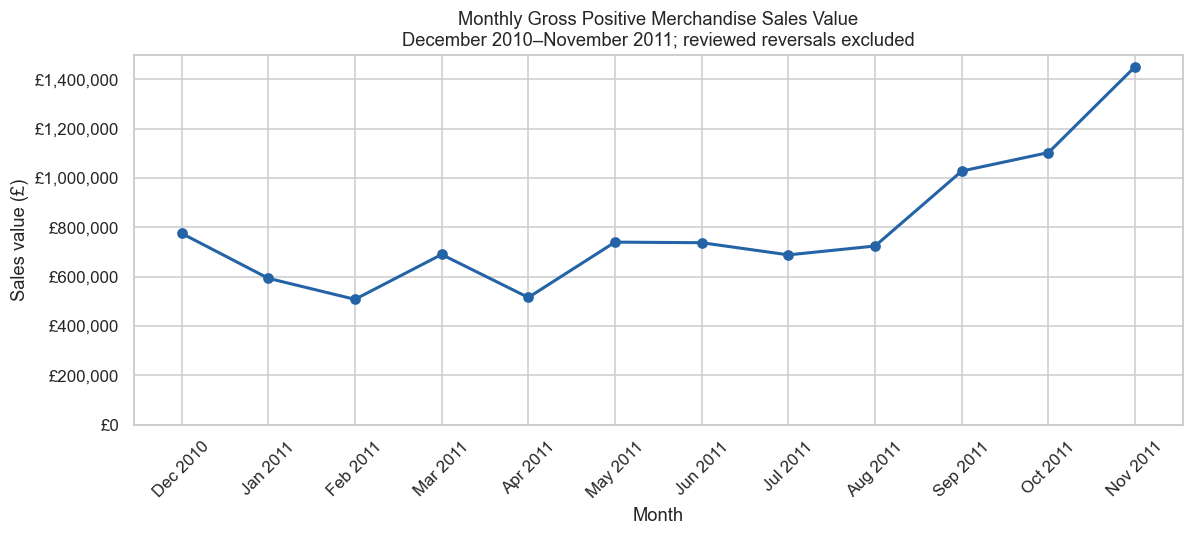

In [17]:
from matplotlib.ticker import StrMethodFormatter

Path("charts").mkdir(exist_ok=True)

month_labels = monthly_summary.index.strftime("%b %Y")

fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    month_labels,
    monthly_summary["SalesValue"],
    marker="o",
    linewidth=2,
    color="#2463A6"
)

ax.set_title(
    "Monthly Gross Positive Merchandise Sales Value\n"
    "December 2010–November 2011; reviewed reversals excluded"
)
ax.set_xlabel("Month")
ax.set_ylabel("Sales value (£)")
ax.yaxis.set_major_formatter(StrMethodFormatter("£{x:,.0f}"))
ax.set_ylim(bottom=0)
ax.tick_params(axis="x", rotation=45)

fig.tight_layout()
fig.savefig(
    Path("charts") / "01_monthly_sales_value.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### Interpretation of Monthly Sales Value

Gross positive merchandise sales value fluctuated across the period,
then increased each month from August through November 2011.

November had the highest sales value at £1,452,115.98, while February
had the lowest at £507,799.87. December 2011 was excluded because it
contains only part of the month.

The late-period increase could be consistent with holiday purchasing,
but this dataset does not establish the cause or demonstrate a
recurring seasonal pattern across multiple years.

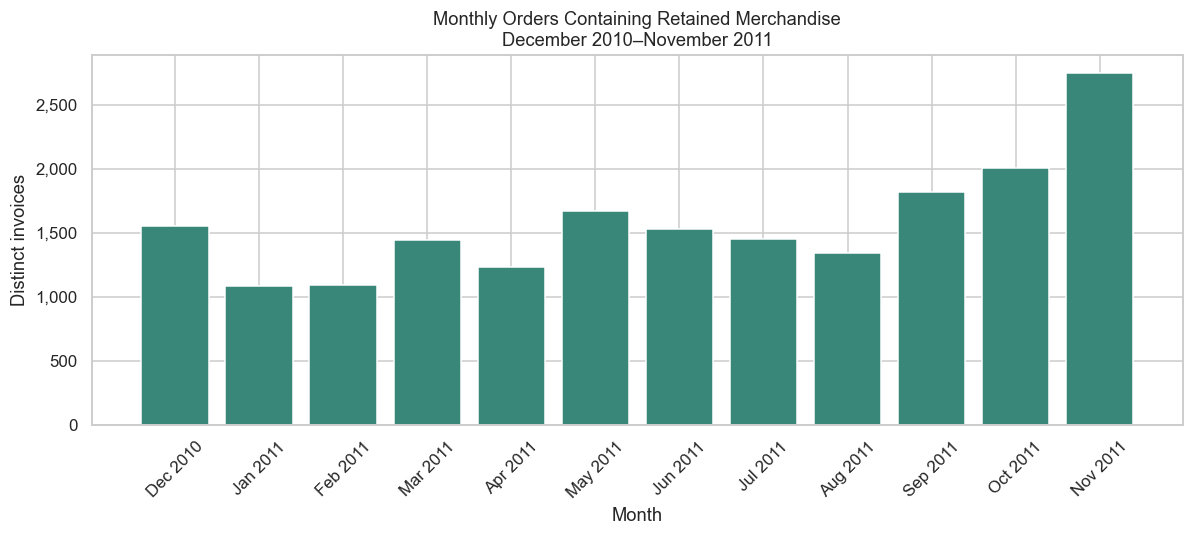

In [18]:
fig, ax = plt.subplots(figsize=(11, 5))

ax.bar(
    month_labels,
    monthly_summary["OrderCount"],
    color="#398779"
)

ax.set_title(
    "Monthly Orders Containing Retained Merchandise\n"
    "December 2010–November 2011"
)
ax.set_xlabel("Month")
ax.set_ylabel("Distinct invoices")
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.tick_params(axis="x", rotation=45)

fig.tight_layout()
fig.savefig(
    Path("charts") / "02_monthly_order_count.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### Interpretation of Monthly Order Counts

November also had the highest number of retained merchandise orders,
with 2,751 distinct invoices. January had the lowest count, with 1,080.

From October to November, order count increased from 2,005 to 2,751
while average merchandise order value fell from £550.28 to £527.85.
The increase in November's sales value therefore coincided with
more orders rather than a higher average order value.

### Answer to Research Question 1

Monthly sales value and order counts varied throughout the period,
with both reaching their highest levels in November 2011. Sales value
rose consistently from August through November. These findings describe
the retained merchandise records and do not measure net revenue
after all refunds.

### Research Question 2
Which products generate the highest sales value, and how do their
rankings compare with rankings by units sold?

I will group products by StockCode and calculate total merchandise
sales value and units sold. A product's most frequent description
will be used as its display label, so variations in description do
not split one product into several groups.

This analysis uses the full observed period, December 1, 2010 through
December 9, 2011. The monthly comparison used complete months only.

In [19]:
# Select the most frequent description for each product code.
description_counts = (
    analysis_sales.groupby(["StockCode", "Description"])
    .size()
    .reset_index(name="Frequency")
)

product_labels = (
    description_counts
    .sort_values(
        ["StockCode", "Frequency", "Description"],
        ascending=[True, False, True]
    )
    .drop_duplicates(subset="StockCode")
    .set_index("StockCode")["Description"]
)

product_summary = (
    analysis_sales.groupby("StockCode")
    .agg(
        SalesValue=("SalesValue", "sum"),
        UnitsSold=("Quantity", "sum"),
        OrderCount=("InvoiceNo", "nunique")
    )
    .join(product_labels)
)

product_summary["SalesValueRank"] = (
    product_summary["SalesValue"]
    .rank(method="min", ascending=False)
    .astype(int)
)

product_summary["UnitsSoldRank"] = (
    product_summary["UnitsSold"]
    .rank(method="min", ascending=False)
    .astype(int)
)

top_value_products = (
    product_summary
    .sort_values("SalesValue", ascending=False)
    .head(10)
)

top_unit_products = (
    product_summary
    .sort_values("UnitsSold", ascending=False)
    .head(10)
)

display_columns = [
    "Description", "SalesValue", "UnitsSold",
    "OrderCount", "SalesValueRank", "UnitsSoldRank"
]

print("Top 10 products by sales value:")
display(top_value_products[display_columns].round(2))

print("Top 10 products by units sold:")
display(top_unit_products[display_columns].round(2))

overlap = (
    set(top_value_products.index)
    & set(top_unit_products.index)
)

print(f"Products appearing in both top-10 lists: {len(overlap)}")

Top 10 products by sales value:
Top 10 products by units sold:
Products appearing in both top-10 lists: 5


,Description,SalesValue,UnitsSold,OrderCount,SalesValueRank,UnitsSoldRank
StockCode,,,,,,
22423,REGENCY CAKESTAND 3 TIER,174156.54,13851,1988,1,37
85123A,WHITE HANGING HEART T-LIGHT HOLDER,106415.23,37933,2265,2,4
47566,PARTY BUNTING,99445.23,18283,1685,3,20
85099B,JUMBO BAG RED RETROSPOT,94159.81,48371,2089,4,3
23084,RABBIT NIGHT LIGHT,66870.03,30739,994,5,7
22086,PAPER CHAIN KIT 50'S CHRISTMAS,64875.59,19329,1160,6,18
84879,ASSORTED COLOUR BIRD ORNAMENT,58927.62,36362,1455,7,6
79321,CHILLI LIGHTS,54096.36,10302,661,8,82
22502,PICNIC BASKET WICKER SMALL,51408.77,1937,463,9,739


,Description,SalesValue,UnitsSold,OrderCount,SalesValueRank,UnitsSoldRank
StockCode,,,,,,
22197,POPCORN HOLDER,51334.47,56898,1392,10,1
84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,13814.01,54951,535,145,2
85099B,JUMBO BAG RED RETROSPOT,94159.81,48371,2089,4,3
85123A,WHITE HANGING HEART T-LIGHT HOLDER,106415.23,37933,2265,2,4
21212,PACK OF 72 RETROSPOT CAKE CASES,21246.45,36396,1320,85,5
84879,ASSORTED COLOUR BIRD ORNAMENT,58927.62,36362,1455,7,6
23084,RABBIT NIGHT LIGHT,66870.03,30739,994,5,7
22492,MINI PAINT SET VINTAGE,16937.82,26633,380,114,8
22616,PACK OF 12 LONDON TISSUES,7975.98,26119,512,297,9


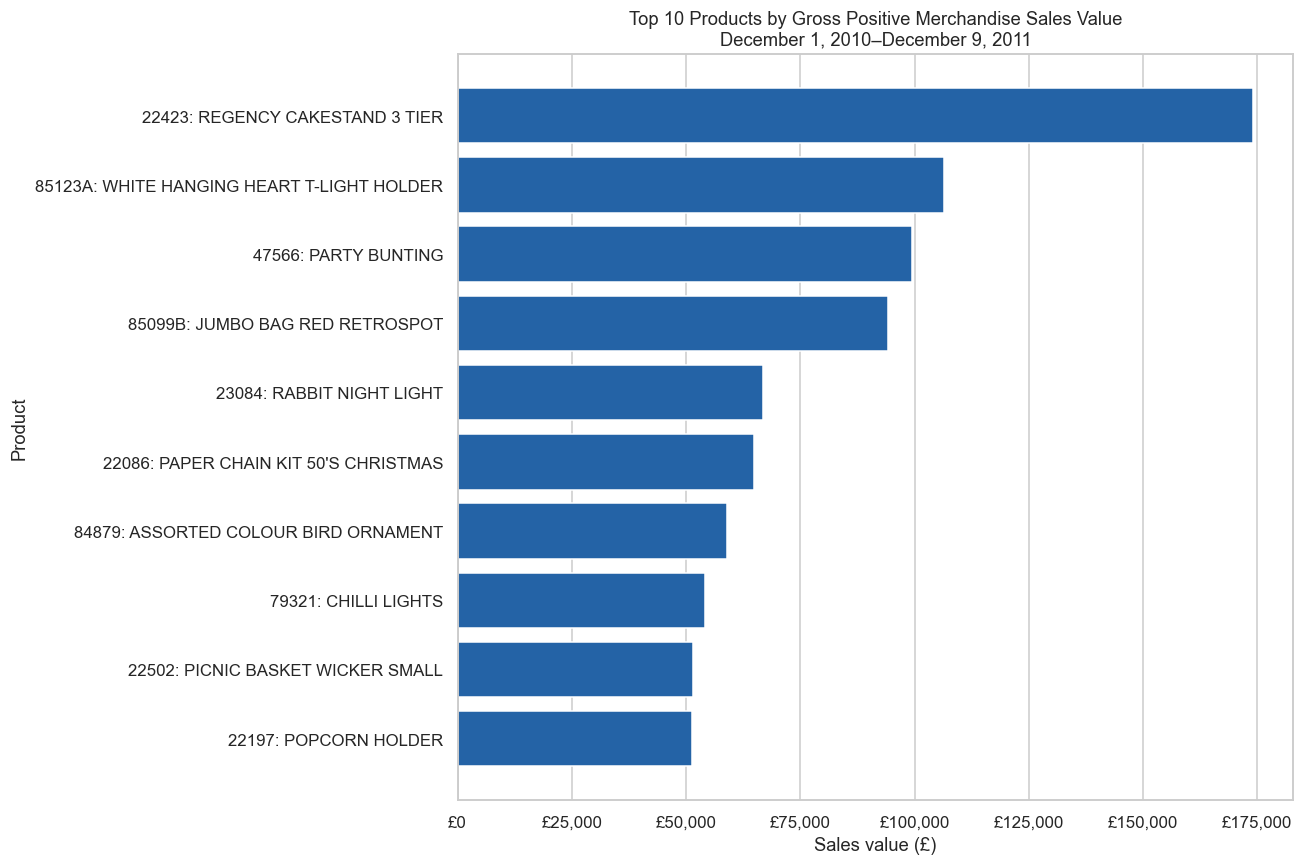

In [20]:
import textwrap

plot_data = top_value_products.sort_values("SalesValue").copy()

labels = [
    textwrap.fill(f"{code}: {description}", width=42)
    for code, description in zip(
        plot_data.index, plot_data["Description"]
    )
]

fig, ax = plt.subplots(figsize=(12, 8))

ax.barh(
    labels,
    plot_data["SalesValue"],
    color="#2463A6"
)

ax.set_title(
    "Top 10 Products by Gross Positive Merchandise Sales Value\n"
    "December 1, 2010–December 9, 2011"
)
ax.set_xlabel("Sales value (£)")
ax.set_ylabel("Product")
ax.xaxis.set_major_formatter(StrMethodFormatter("£{x:,.0f}"))
ax.grid(axis="y", visible=False)

fig.tight_layout()
fig.savefig(
    Path("charts") / "03_top_products_sales_value.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### Interpretation of Product Sales Value

Regency Cakestand 3 Tier generated the highest gross positive merchandise
sales value at £174,156.54. White Hanging Heart T-Light Holder ranked
second at £106,415.23.

Regency Cakestand ranked only 37th in units sold, showing that the product
with the highest sales value did not have the highest sales volume.
These figures measure sales value rather than profit because product
costs are not available.

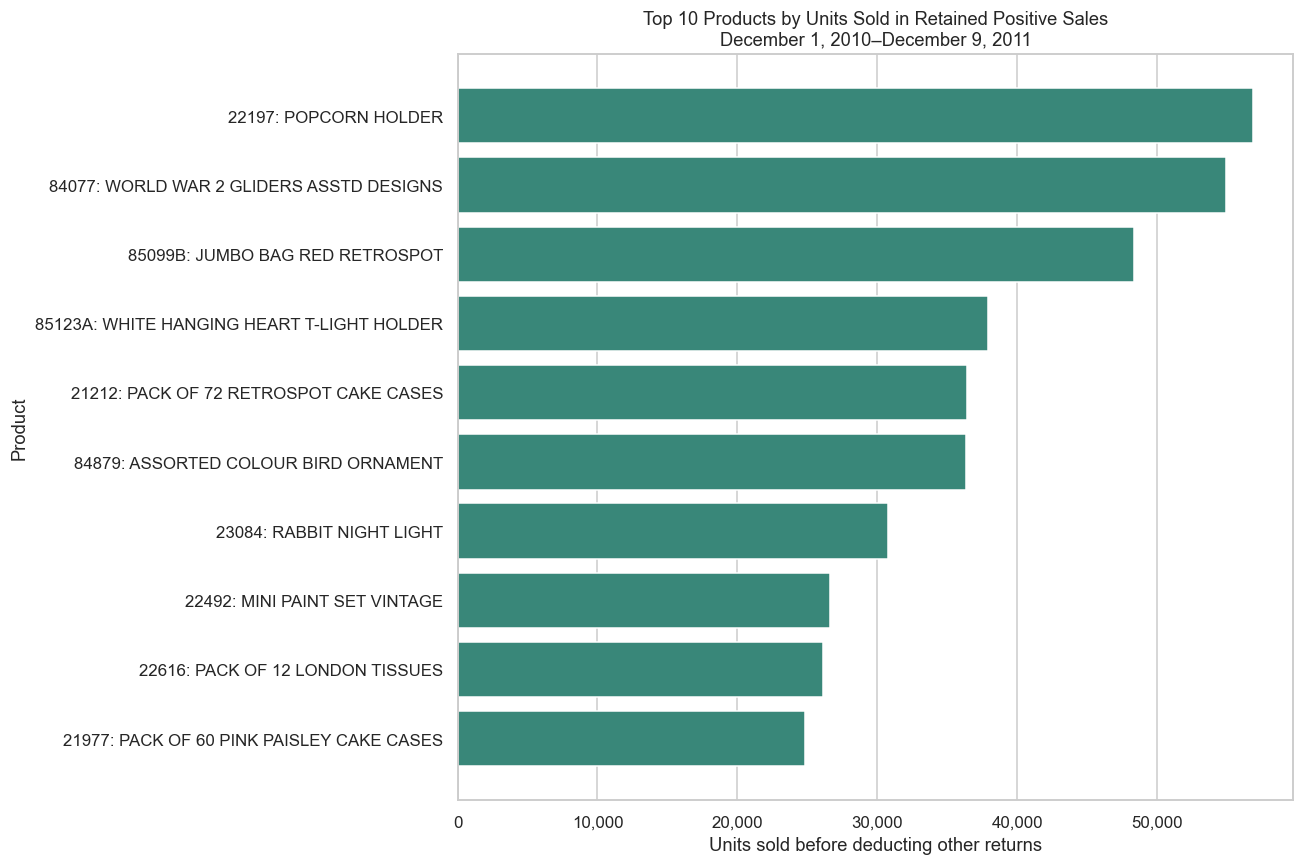

In [21]:
plot_data = top_unit_products.sort_values("UnitsSold").copy()

labels = [
    textwrap.fill(f"{code}: {description}", width=42)
    for code, description in zip(
        plot_data.index, plot_data["Description"]
    )
]

fig, ax = plt.subplots(figsize=(12, 8))

ax.barh(
    labels,
    plot_data["UnitsSold"],
    color="#398779"
)

ax.set_title(
    "Top 10 Products by Units Sold in Retained Positive Sales\n"
    "December 1, 2010–December 9, 2011"
)
ax.set_xlabel("Units sold before deducting other returns")
ax.set_ylabel("Product")
ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="y", visible=False)

fig.tight_layout()
fig.savefig(
    Path("charts") / "04_top_products_units_sold.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### Interpretation of Product Units Sold

Popcorn Holder had the highest recorded sales volume at 56,898 units,
followed by World War 2 Gliders Assorted Designs at 54,951 units.

Popcorn Holder ranked 10th in sales value, while World War 2 Gliders
ranked 145th. Five products appeared in both top-10 lists. This shows
that high unit volume and high sales value identify different aspects
of product performance.

Quantity refers to the dataset's recorded selling units. A unit can
represent a packaged product, so quantities should not be interpreted
as comparable counts of individual physical pieces across all products.

### Answer to Research Question 2

Regency Cakestand 3 Tier led in sales value, while Popcorn Holder led
in units sold. The rankings differed substantially, with only five
products shared between the two top-10 lists. Both sales value and
volume are therefore useful when describing product performance.

### Research Question 3
Which countries contribute the most sales value, and how does average
order value differ across the leading markets?

I will compare countries using total gross positive merchandise sales
value, distinct invoice counts, and average merchandise order value
over the full observed period.

Leading markets are defined as the ten countries with the highest
sales value. Average order value includes retained merchandise lines
and excludes postage, fees, and other excluded entries.

In [22]:
# Check that an invoice is assigned to only one country.
countries_per_invoice = (
    analysis_sales.groupby("InvoiceNo")["Country"].nunique()
)

print(
    "Invoices appearing in multiple countries:",
    countries_per_invoice.gt(1).sum()
)
print("Rows missing country:", analysis_sales["Country"].isna().sum())

# Create one record per invoice.
orders = (
    analysis_sales.groupby("InvoiceNo")
    .agg(
        Country=("Country", "first"),
        OrderValue=("SalesValue", "sum")
    )
    .reset_index()
)

country_summary = (
    orders.groupby("Country")
    .agg(
        SalesValue=("OrderValue", "sum"),
        OrderCount=("InvoiceNo", "nunique"),
        AverageOrderValue=("OrderValue", "mean"),
        MedianOrderValue=("OrderValue", "median")
    )
    .sort_values("SalesValue", ascending=False)
)

country_summary["SalesSharePct"] = (
    100 * country_summary["SalesValue"]
    / country_summary["SalesValue"].sum()
)

top_countries = country_summary.head(10).copy()

display(top_countries.round(2))

Invoices appearing in multiple countries: 0
Rows missing country: 0


,SalesValue,OrderCount,AverageOrderValue,MedianOrderValue,SalesSharePct
Country,,,,,
United Kingdom,8478790.47,17899,473.70,299.60,84.77
Netherlands,283889.34,93,3052.57,814.62,2.84
EIRE,270850.86,282,960.46,624.71,2.71
Germany,205381.15,443,463.61,318.85,2.05
France,184493.00,382,482.97,344.57,1.84
Australia,138103.81,56,2466.14,430.45,1.38
Spain,55706.56,88,633.03,363.06,0.56
Switzerland,53065.60,50,1061.31,557.18,0.53
Japan,37416.37,19,1969.28,1607.04,0.37


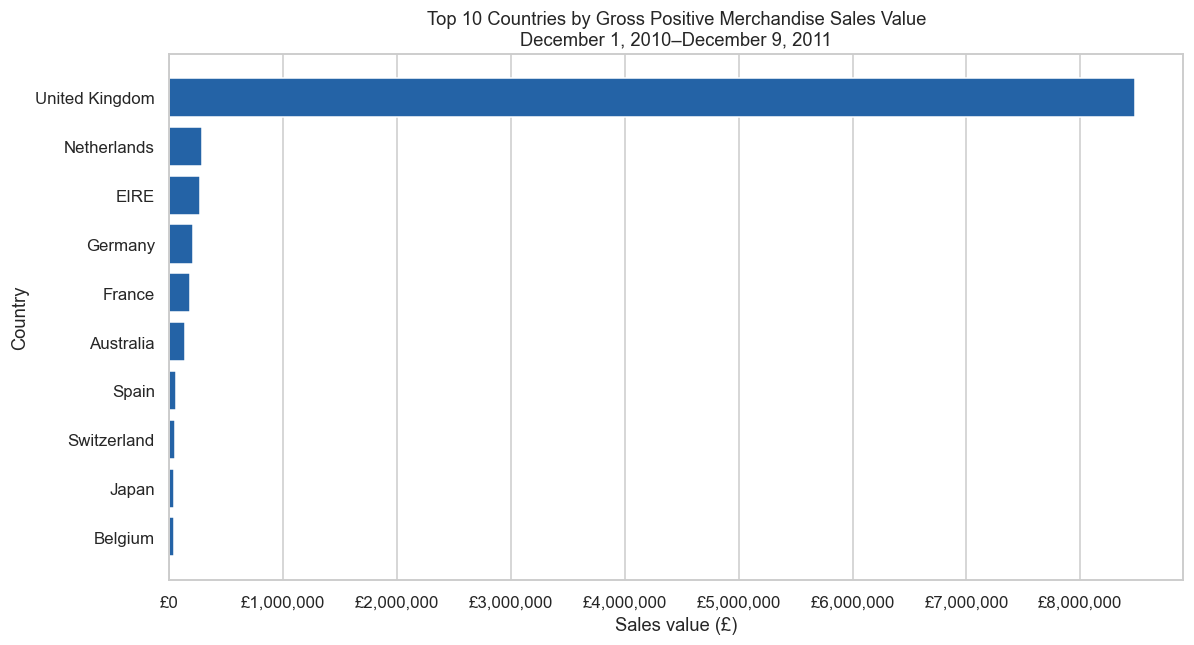

In [23]:
plot_data = top_countries.sort_values("SalesValue")

fig, ax = plt.subplots(figsize=(11, 6))

ax.barh(
    plot_data.index,
    plot_data["SalesValue"],
    color="#2463A6"
)

ax.set_title(
    "Top 10 Countries by Gross Positive Merchandise Sales Value\n"
    "December 1, 2010–December 9, 2011"
)
ax.set_xlabel("Sales value (£)")
ax.set_ylabel("Country")
ax.xaxis.set_major_formatter(StrMethodFormatter("£{x:,.0f}"))
ax.grid(axis="y", visible=False)

fig.tight_layout()
fig.savefig(
    Path("charts") / "05_country_sales_value.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### Interpretation of Country Sales Value

The United Kingdom contributed £8,478,790.47, representing 84.77% of
gross positive merchandise sales value in the analysis dataset.

The Netherlands ranked second at £283,889.34, followed by EIRE at
£270,850.86. The chart shows that this retailer's recorded sales were
heavily concentrated in the UK.

These percentages describe the retailer's retained merchandise records,
not each country's share of the wider retail market.

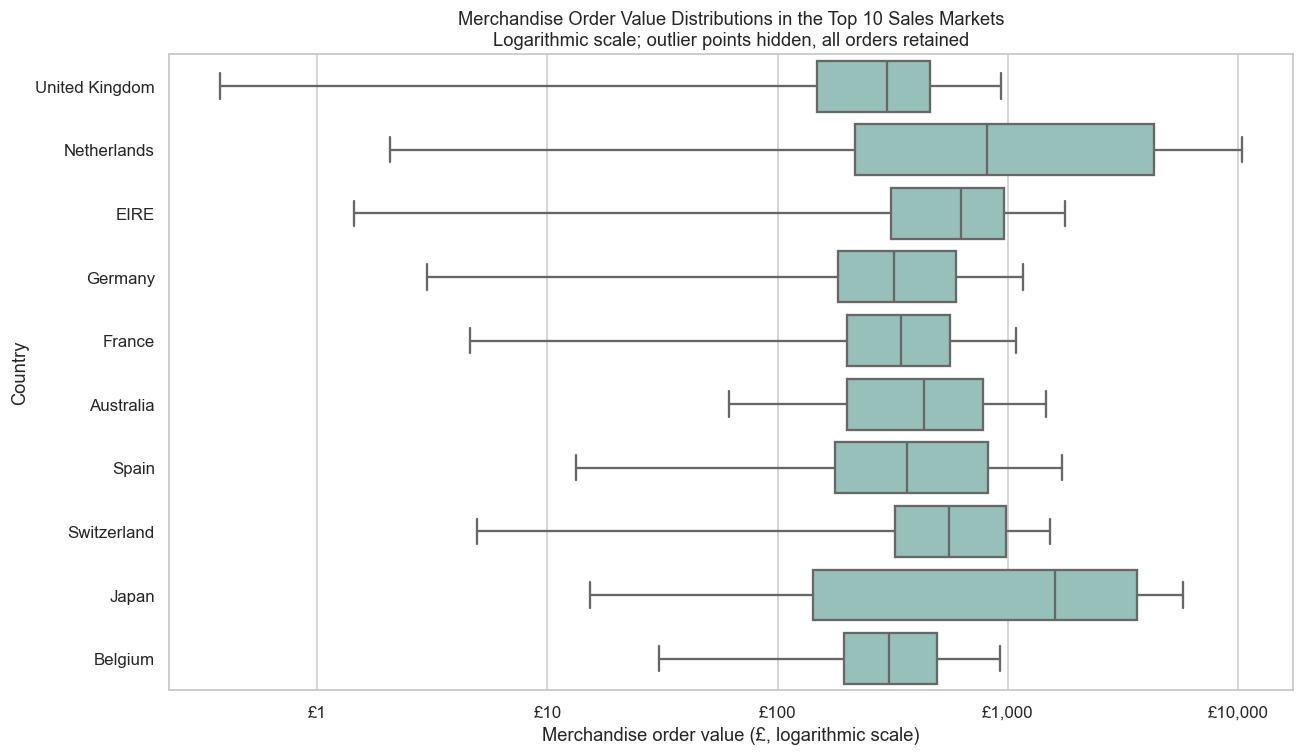

In [24]:
country_order = top_countries.index.tolist()

leading_market_orders = orders.loc[
    orders["Country"].isin(country_order)
].copy()

fig, ax = plt.subplots(figsize=(12, 7))

sns.boxplot(
    data=leading_market_orders,
    x="OrderValue",
    y="Country",
    order=country_order,
    color="#8FC7BD",
    showfliers=False,
    ax=ax
)

# A log scale makes differences across countries easier to compare.
ax.set_xscale("log")
ax.set_title(
    "Merchandise Order Value Distributions in the Top 10 Sales Markets\n"
    "Logarithmic scale; outlier points hidden, all orders retained"
)
ax.set_xlabel("Merchandise order value (£, logarithmic scale)")
ax.set_ylabel("Country")
ax.xaxis.set_major_formatter(StrMethodFormatter("£{x:,.0f}"))
ax.grid(axis="y", visible=False)

fig.tight_layout()
fig.savefig(
    Path("charts") / "06_country_order_value_boxplot.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### Interpretation of Merchandise Order Values

Among the ten countries with the highest sales value, the Netherlands
had the highest average merchandise order value at £3,052.57, compared
with £473.70 for the United Kingdom.

The Netherlands' median order value was £814.62, substantially below
its mean. Australia's mean was £2,466.14, compared with a median of
£430.45. These differences indicate that large orders pull the averages
upward, so the mean alone does not describe a typical order well.

Japan had the highest median among these ten markets at £1,607.04,
but this estimate is based on only 19 orders. Country comparisons
should therefore consider both the distribution and the order count.

The boxplot uses a logarithmic scale. Each box shows the middle 50%
of order values, and the line inside marks the median. Outlier points
are hidden for readability but remain included in the calculations.

### Answer to Research Question 3

The United Kingdom contributed the most sales value, followed by the
Netherlands and EIRE. Among the ten leading sales markets, average
order value was highest in the Netherlands. High total sales value
and high average order value therefore describe different aspects
of market performance.

## 6. Limitations

1. **One retailer and a historical period.**
   The dataset covers one UK-based retailer from December 2010 to
   December 2011. Results cannot be assumed to represent today's
   retail market or other businesses.

2. **Sales value is not net revenue or profit.**
   The analysis excludes cancellations, nonpositive quantities and
   prices, non-merchandise entries, and two reviewed reversed purchases.
   Other returns were not systematically matched to original purchases.
   Product costs are unavailable, so profitability cannot be assessed.

3. **Duplicate removal is an assumption.**
   Identical rows may be errors or legitimate repeated invoice lines.
   Removing exact duplicates reduced positive-sales value by 0.23%,
   but this small overall effect does not prove individual product
   or country rankings are unaffected.

4. **Country sample sizes differ.**
   Some countries have few orders, and large purchases can strongly
   influence their average order values. Means were therefore
   considered alongside medians and order counts.

5. **Limited evidence about seasonality and causes.**
   December 2011 is incomplete and was excluded from monthly comparisons.
   Only one full annual cycle is available, so recurring seasonality
   and the causes of changes cannot be established.

6. **Missing customer identities.**
   Records with missing CustomerID were retained for invoice, product,
   and country analysis. This limits any conclusions about unique
   customers, repeat purchasing, or customer retention.

## 7. Conclusion

This project used Pandas, Matplotlib, and Seaborn to inspect, prepare,
analyze, and visualize online retail transaction data.

November 2011 had the highest sales value and order count among the
complete months analyzed. Regency Cakestand 3 Tier led product sales
value, while Popcorn Holder led units sold. Only five products appeared
in both top-10 lists, demonstrating the value of examining both
monetary performance and sales volume.

The United Kingdom contributed 84.77% of retained merchandise sales
value. The Netherlands had the highest average order value among the
ten leading sales markets, although large orders and unequal sample
sizes affect these comparisons.

The project demonstrated the importance of defining metrics, documenting
cleaning decisions, and interpreting charts alongside supporting tables.
The results describe historical gross positive merchandise sales after
the stated exclusions, rather than net revenue, profit, or causal effects.

## 8. References

- Chen, D. (2015). Online Retail [Dataset]. UCI Machine Learning Repository.
  https://doi.org/10.24432/C5BW33

- Dataset page and variable descriptions:
  https://archive.ics.uci.edu/dataset/352/online+retail

### Acknowledgment of Assistance

I used OpenAI for guidance with Python code and explanations, alongside YouTube tutorials, textbook materials, and class slides covering Pandas, data cleaning, and graph creation with Matplotlib and Seaborn. I executed the code in Jupyter Notebook and reviewed the outputs to understand the analysis and findings.

## 9. Validation

The checks below confirm the main filters, analysis period, and reconciliation of summary tables. They establish internal consistency, not that the cleaning assumptions are the only valid choices.

In [25]:
assert len(df_raw) == 541909
assert len(analysis_sales) == 522538
assert analysis_sales["Quantity"].gt(0).all()
assert analysis_sales["UnitPrice"].gt(0).all()
assert analysis_sales[["InvoiceNo", "StockCode", "InvoiceDate", "Country"]].notna().all().all()
assert not analysis_sales["InvoiceNo"].str.startswith("C").any()
assert not analysis_sales["StockCode"].isin(excluded_codes).any()
assert not analysis_sales["StockCode"].str.startswith("GIFT_").any()
assert monthly_summary.index.equals(pd.period_range("2010-12", "2011-11", freq="M"))
assert analysis_sales.groupby("InvoiceNo")["Country"].nunique().eq(1).all()
total_value = analysis_sales["SalesValue"].sum()
assert abs(total_value - 10001566.12) < 0.01
assert abs(product_summary["SalesValue"].sum() - total_value) < 0.01
assert abs(country_summary["SalesValue"].sum() - total_value) < 0.01
assert abs(monthly_summary["SalesValue"].sum() - complete_month_sales["SalesValue"].sum()) < 0.01
print("All validation checks passed.")

All validation checks passed.
